In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:,.2f}'.format)

print("Libraries imported successfully!")


Matplotlib is building the font cache; this may take a moment.


Libraries imported successfully!


In [2]:

df = pd.read_csv("marketing-campaigns-1000.csv")

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

df.head()


Dataset loaded successfully!
Rows and columns: (1000, 14)


,campaign_id,campaign_name,channel,start_date,end_date,budget,spend,impressions,clicks,ctr,conversions,cpa,revenue,roas
0,MC-0501,Display - Loyalty - Q3 2023,Display,2023-09-02,2023-10-19,15783,"13,877.61",3469403,19871,0.01,232,59.82,"26,971.70",1.94
1,MC-0502,Display - New Product - Q2 2023,Display,2023-04-12,2023-05-09,10637,"8,170.24",2042560,10623,0.01,145,56.35,"20,201.74",2.47
2,MC-0503,Affiliate - Brand - Q4 2024,Affiliate,2024-10-14,2024-11-09,19605,"16,958.03",2826338,43107,0.02,578,29.34,"53,171.73",3.14
3,MC-0504,Affiliate - Spring Sale - Q4 2023,Affiliate,2023-10-15,2023-11-01,12148,"11,548.22",1924703,20874,0.01,353,32.71,"33,840.84",2.93
4,MC-0505,Display - New Product - Q1 2024,Display,2024-01-08,2024-02-08,7439,"6,031.07",1507768,10021,0.01,154,39.16,"15,443.59",2.56


In [3]:

# View column names and data types
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   campaign_id    1000 non-null   str    
 1   campaign_name  1000 non-null   str    
 2   channel        1000 non-null   str    
 3   start_date     1000 non-null   str    
 4   end_date       1000 non-null   str    
 5   budget         1000 non-null   int64  
 6   spend          1000 non-null   float64
 7   impressions    1000 non-null   int64  
 8   clicks         1000 non-null   int64  
 9   ctr            1000 non-null   float64
 10  conversions    1000 non-null   int64  
 11  cpa            1000 non-null   float64
 12  revenue        1000 non-null   float64
 13  roas           1000 non-null   float64
dtypes: float64(5), int64(4), str(5)
memory usage: 109.5 KB


In [4]:

# Generate descriptive statistics
df.describe()


,budget,spend,impressions,clicks,ctr,conversions,cpa,revenue,roas
count,"1,000.00","1,000.00","1,000.00","1,000.00","1,000.00","1,000.00","1,000.00","1,000.00","1,000.00"
mean,"10,684.90","9,378.48","1,114,708.98","13,884.81",0.02,299.60,43.00,"31,757.42",3.39
std,"5,101.26","4,679.04","907,816.43","10,448.55",0.01,237.37,25.48,"27,211.21",2.10
min,895.00,818.09,"55,719.00",859.00,0.00,14.00,10.09,"1,122.02",0.43
25%,"6,378.50","5,659.24","433,801.75","6,018.00",0.01,126.00,23.77,"12,837.97",1.82
50%,"10,632.00","9,105.28","874,097.50","11,355.00",0.01,235.50,36.71,"23,838.49",2.91
75%,"14,822.25","12,858.79","1,530,139.75","18,756.75",0.02,390.00,56.17,"42,485.37",4.45
max,"19,977.00","20,221.00","4,682,970.00","63,533.00",0.05,"1,362.00",149.56,"176,494.77",12.32


In [5]:

# Check for missing values
print("Missing values by column:")
print(df.isnull().sum())

# Check for duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Check for duplicate campaign IDs
print("Duplicate campaign IDs:", df["campaign_id"].duplicated().sum())

# Check unique values in channel
print("\nMarketing channels:")
print(df["channel"].value_counts())

Missing values by column:
campaign_id      0
campaign_name    0
channel          0
start_date       0
end_date         0
budget           0
spend            0
impressions      0
clicks           0
ctr              0
conversions      0
cpa              0
revenue          0
roas             0
dtype: int64

Duplicate rows: 0
Duplicate campaign IDs: 0

Marketing channels:
channel
Video          182
Paid search    172
Display        171
Affiliate      162
Email          157
Social         156
Name: count, dtype: int64


In [6]:

# Recalculate performance metrics
df["calculated_ctr"] = df["clicks"] / df["impressions"]
df["calculated_cpa"] = df["spend"] / df["conversions"]
df["calculated_roas"] = df["revenue"] / df["spend"]

# Compare calculated metrics with original columns
print("CTR discrepancies:", 
      (~np.isclose(df["ctr"], df["calculated_ctr"], rtol=0.01)).sum())

print("CPA discrepancies:", 
      (~np.isclose(df["cpa"], df["calculated_cpa"], rtol=0.01)).sum())

print("ROAS discrepancies:", 
      (~np.isclose(df["roas"], df["calculated_roas"], rtol=0.01)).sum())

CTR discrepancies: 19
CPA discrepancies: 0
ROAS discrepancies: 0


In [7]:

# Display campaigns where CTR does not match our calculation
ctr_issues = df[
    ~np.isclose(
        df["ctr"],
        df["calculated_ctr"],
        rtol=0.01
    )
].copy()

ctr_issues[
    ["campaign_id", "clicks", "impressions", "ctr", "calculated_ctr"]
]

,campaign_id,clicks,impressions,ctr,calculated_ctr
6,MC-0507,17826,3915025,0.00,0.00
19,MC-0520,8292,2051043,0.00,0.00
64,MC-0565,8450,2591913,0.00,0.00
69,MC-0570,2114,649190,0.00,0.00
136,MC-0637,7563,2469003,0.00,0.00
256,MC-0757,15734,3795698,0.00,0.00
280,MC-0781,9690,2277710,0.00,0.00
287,MC-0788,13382,3303773,0.00,0.00
320,MC-0821,13710,4230273,0.00,0.00
338,MC-0839,2234,708790,0.00,0.00


In [8]:

# Display CTR values with six decimal places
pd.set_option('display.precision', 6)

ctr_issues[
    ["campaign_id", "clicks", "impressions", "ctr", "calculated_ctr"]
]

,campaign_id,clicks,impressions,ctr,calculated_ctr
6,MC-0507,17826,3915025,0.00,0.00
19,MC-0520,8292,2051043,0.00,0.00
64,MC-0565,8450,2591913,0.00,0.00
69,MC-0570,2114,649190,0.00,0.00
136,MC-0637,7563,2469003,0.00,0.00
256,MC-0757,15734,3795698,0.00,0.00
280,MC-0781,9690,2277710,0.00,0.00
287,MC-0788,13382,3303773,0.00,0.00
320,MC-0821,13710,4230273,0.00,0.00
338,MC-0839,2234,708790,0.00,0.00


In [9]:

# Show the actual values for the first five discrepancies
for _, row in ctr_issues.head(5).iterrows():
    print("Campaign:", row["campaign_id"])
    print("Original CTR:", repr(row["ctr"]))
    print("Calculated CTR:", repr(row["calculated_ctr"]))
    print("Difference:", repr(row["ctr"] - row["calculated_ctr"]))
    print("---")

Campaign: MC-0507
Original CTR: 0.0046
Calculated CTR: 0.004553227629453196
Difference: 4.677237054680379e-05
---
Campaign: MC-0520
Original CTR: 0.004
Calculated CTR: 0.004042821140268634
Difference: -4.282114026863369e-05
---
Campaign: MC-0565
Original CTR: 0.0033
Calculated CTR: 0.0032601402902026418
Difference: 3.9859709797358204e-05
---
Campaign: MC-0570
Original CTR: 0.0033
Calculated CTR: 0.0032563656248555894
Difference: 4.363437514441062e-05
---
Campaign: MC-0637
Original CTR: 0.0031
Calculated CTR: 0.003063179753123022
Difference: 3.682024687697797e-05
---



### CTR Validation

- 1,000 campaign records were checked.
- CPA and ROAS matched independently recalculated values.
- 19 CTR values differed slightly from recalculated values.
- Investigation showed that the differences were consistent with rounding to four decimal places.
- No corrections were necessary because the original values were reasonably rounded.

In [10]:

# Convert dates to datetime
df["start_date"] = pd.to_datetime(df["start_date"])
df["end_date"] = pd.to_datetime(df["end_date"])

# Check date order
invalid_dates = (df["end_date"] < df["start_date"]).sum()

# Check numerical relationships
invalid_clicks = (df["clicks"] > df["impressions"]).sum()
invalid_conversions = (df["conversions"] > df["clicks"]).sum()
invalid_spend = (df["spend"] <= 0).sum()

print("End dates before start dates:", invalid_dates)
print("Clicks greater than impressions:", invalid_clicks)
print("Conversions greater than clicks:", invalid_conversions)
print("Zero or negative spend:", invalid_spend)

End dates before start dates: 0
Clicks greater than impressions: 0
Conversions greater than clicks: 0
Zero or negative spend: 0


In [11]:

# Calculate campaign duration
df["campaign_duration_days"] = (
    df["end_date"] - df["start_date"]
).dt.days

# Extract date components
df["start_year"] = df["start_date"].dt.year
df["start_month"] = df["start_date"].dt.month
df["start_quarter"] = df["start_date"].dt.quarter

# Preview the new columns
df[[
    "campaign_id",
    "start_date",
    "end_date",
    "campaign_duration_days",
    "start_year",
    "start_month",
    "start_quarter"
]].head()

,campaign_id,start_date,end_date,campaign_duration_days,start_year,start_month,start_quarter
0,MC-0501,2023-09-02,2023-10-19,47,2023,9,3
1,MC-0502,2023-04-12,2023-05-09,27,2023,4,2
2,MC-0503,2024-10-14,2024-11-09,26,2024,10,4
3,MC-0504,2023-10-15,2023-11-01,17,2023,10,4
4,MC-0505,2024-01-08,2024-02-08,31,2024,1,1


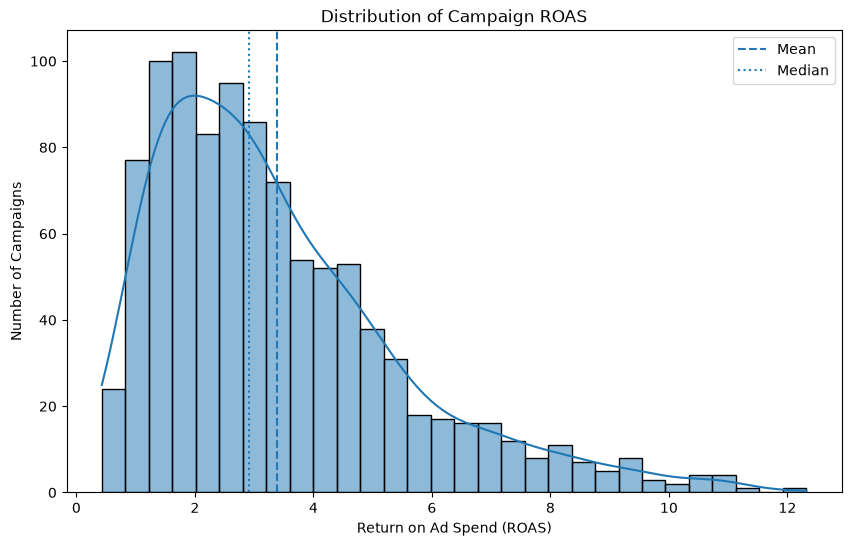

In [12]:

plt.figure(figsize=(10, 6))

sns.histplot(data=df, x="roas", bins=30, kde=True)

plt.title("Distribution of Campaign ROAS")
plt.xlabel("Return on Ad Spend (ROAS)")
plt.ylabel("Number of Campaigns")
plt.axvline(df["roas"].mean(), linestyle="--", label="Mean")
plt.axvline(df["roas"].median(), linestyle=":", label="Median")
plt.legend()

plt.show()

In [13]:

print("Mean ROAS:", df["roas"].mean())
print("Median ROAS:", df["roas"].median())
print("Lowest ROAS:", df["roas"].min())
print("Highest ROAS:", df["roas"].max())

print("\nROAS Summary:")
print(df["roas"].describe())

Mean ROAS: 3.3886499999999997
Median ROAS: 2.91
Lowest ROAS: 0.43
Highest ROAS: 12.32

ROAS Summary:
count   1,000.00
mean        3.39
std         2.10
min         0.43
25%         1.82
50%         2.91
75%         4.45
max        12.32
Name: roas, dtype: float64


In [14]:

channel_roas = (
    df.groupby("channel")["roas"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
)

print(channel_roas)

             count  mean  median
channel                         
Affiliate      162  5.13    4.67
Email          157  5.08    4.68
Paid search    172  3.71    3.33
Social         156  2.81    2.60
Display        171  1.94    1.78
Video          182  1.93    1.71



### ROAS by Marketing Channel

Affiliate (5.13) and Email (5.08) had the highest average campaign ROAS, followed by Paid Search (3.71). Social (2.81), Display (1.94), and Video (1.93) had lower average returns.

The relatively close mean and median values across channels suggest that the observed performance differences are not solely driven by extreme individual campaigns.

These results identify channel-level performance differences but do not establish that the marketing channel itself caused those differences.

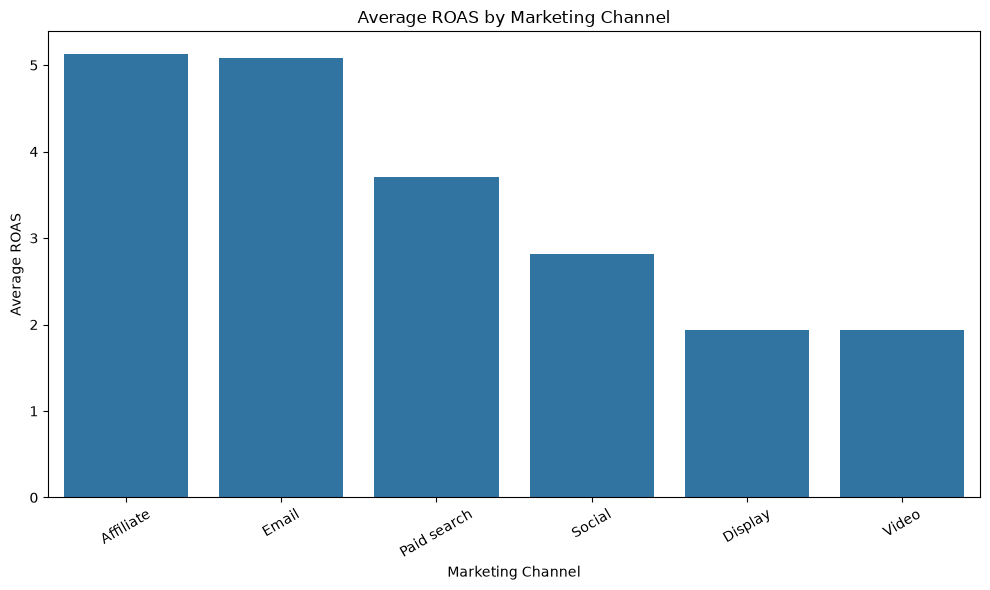

In [15]:

plt.figure(figsize=(10, 6))

sns.barplot(
    data=df,
    x="channel",
    y="roas",
    estimator="mean",
    errorbar=None,
    order=channel_roas.index
)

plt.title("Average ROAS by Marketing Channel")
plt.xlabel("Marketing Channel")
plt.ylabel("Average ROAS")
plt.xticks(rotation=30)
plt.tight_layout()

plt.show()

In [16]:

df["objective"] = df["campaign_name"].str.split(" - ").str[1]

objective_roas = (
    df.groupby("objective")["roas"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
)

print(objective_roas)

                count  mean  median
objective                          
Back to School    130  3.63    2.92
Brand             122  3.59    3.13
Spring Sale       104  3.59    3.06
Clearance         148  3.48    2.99
Holiday           133  3.28    2.78
Retargeting       120  3.22    2.71
Loyalty           119  3.18    2.75
New Product       124  3.12    2.84



### ROAS by Campaign Objective

Back to School campaigns had the highest average ROAS (3.63), followed by Brand and Spring Sale campaigns (3.59 each). New Product campaigns had the lowest average ROAS (3.12).

The difference between the highest and lowest objective averages was 0.51, suggesting that objective-level performance differences were relatively modest in this dataset.

These results are descriptive and do not establish that campaign objective causes changes in ROAS.

In [17]:

channel_objective = (
    df.groupby(["channel", "objective"])["roas"]
    .agg(["count", "mean"])
    .sort_values("mean", ascending=False)
)

print(channel_objective)

                            count  mean
channel     objective                  
Affiliate   Spring Sale        19  6.18
Email       Clearance          23  5.74
Affiliate   Back to School     15  5.72
            Brand              23  5.52
            Clearance          23  5.38
Email       Back to School     24  5.22
            Holiday            21  5.18
            Brand              20  5.09
            New Product        19  5.06
            Loyalty            21  4.98
Affiliate   Retargeting        24  4.95
            New Product        15  4.67
Email       Retargeting        16  4.64
Affiliate   Holiday            20  4.45
            Loyalty            23  4.35
Email       Spring Sale        13  4.20
Paid search Back to School     27  3.99
            Spring Sale        19  3.92
            Clearance          24  3.91
            Brand              26  3.91
            Holiday            23  3.66
            Loyalty            15  3.34
            New Product        18  3.34



### ROAS by Channel and Campaign Objective

The combination of marketing channel and campaign objective revealed substantial performance differences.

Affiliate + Spring Sale had the highest average ROAS (6.18), followed by Email + Clearance (5.74). Display + Spring Sale had the lowest average ROAS (1.61).

Affiliate and Email generally performed well across objectives, while Display and Video consistently recorded lower returns.

This suggests that evaluating campaign objectives independently of their marketing channels can hide important performance differences. Results are descriptive and do not establish causation.

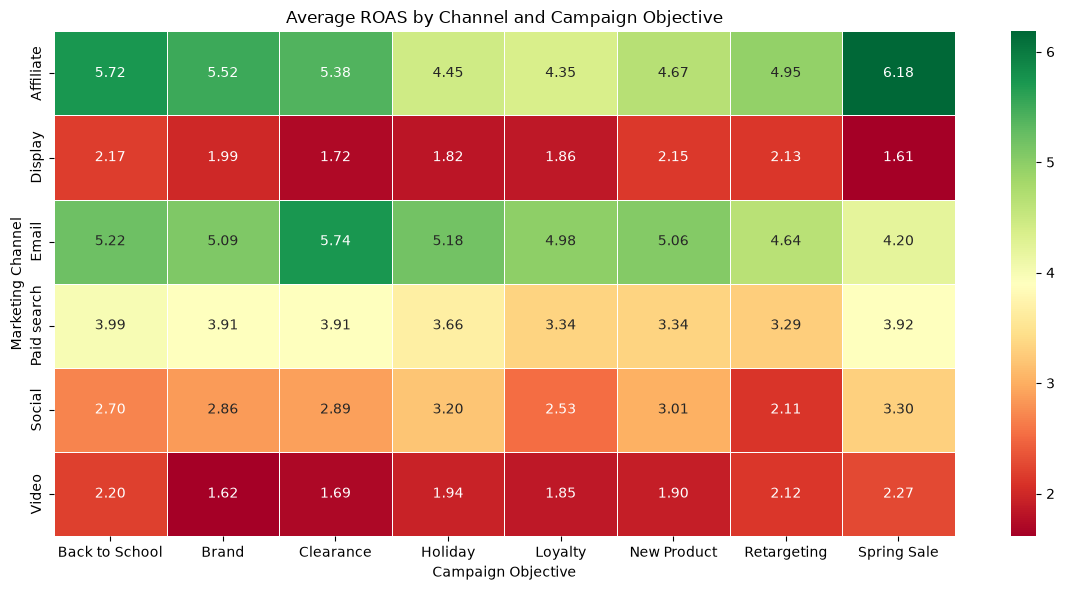

In [18]:

# Create a table of average ROAS by channel and objective
heatmap_data = df.pivot_table(
    index="channel",
    columns="objective",
    values="roas",
    aggfunc="mean"
)

plt.figure(figsize=(12, 6))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".2f",
    cmap="RdYlGn",
    linewidths=0.5
)

plt.title("Average ROAS by Channel and Campaign Objective")
plt.xlabel("Campaign Objective")
plt.ylabel("Marketing Channel")
plt.tight_layout()

plt.show()

In [19]:

monthly_roas = (
    df.groupby("start_month")["roas"]
    .agg(["count", "mean", "median"])
)

print(monthly_roas)

             count  mean  median
start_month                     
1               97  3.12    2.77
2               74  3.91    3.59
3               94  3.42    2.99
4               77  3.68    3.00
5               97  3.15    2.60
6               88  3.24    2.70
7               92  3.41    2.66
8               94  3.71    3.27
9               72  3.21    2.73
10              83  3.26    3.04
11              92  3.33    2.84
12              40  3.27    2.81



### ROAS by Campaign Launch Month

February had the highest average ROAS (3.91), followed by August (3.71) and April (3.68). January had the lowest average ROAS (3.12).

Campaign performance varied across launch months, but the available 2023–2024 data is insufficient to establish a recurring seasonal pattern. December also had a smaller sample size (40 campaigns) than the other months.

In [20]:

duration_roas = (
    df.groupby(
        pd.cut(
            df["campaign_duration_days"],
            bins=[0, 14, 30, 45, 60, 100],
            labels=["1–14 days", "15–30 days", "31–45 days",
                    "46–60 days", "61–100 days"]
        ),
        observed=False
    )["roas"]
    .agg(["count", "mean", "median"])
)

print(duration_roas)

                        count  mean  median
campaign_duration_days                     
1–14 days                  21  3.33    2.95
15–30 days                355  3.30    2.84
31–45 days                312  3.42    2.88
46–60 days                312  3.45    3.00
61–100 days                 0   NaN     NaN



### ROAS by Campaign Duration

Campaigns lasting 46–60 days had the highest average ROAS (3.45), while campaigns lasting 15–30 days had the lowest (3.30).

The difference between these averages was relatively small (0.15), suggesting that campaign duration alone may not be a strong indicator of performance in this dataset.

No campaigns exceeded 60 days in duration.

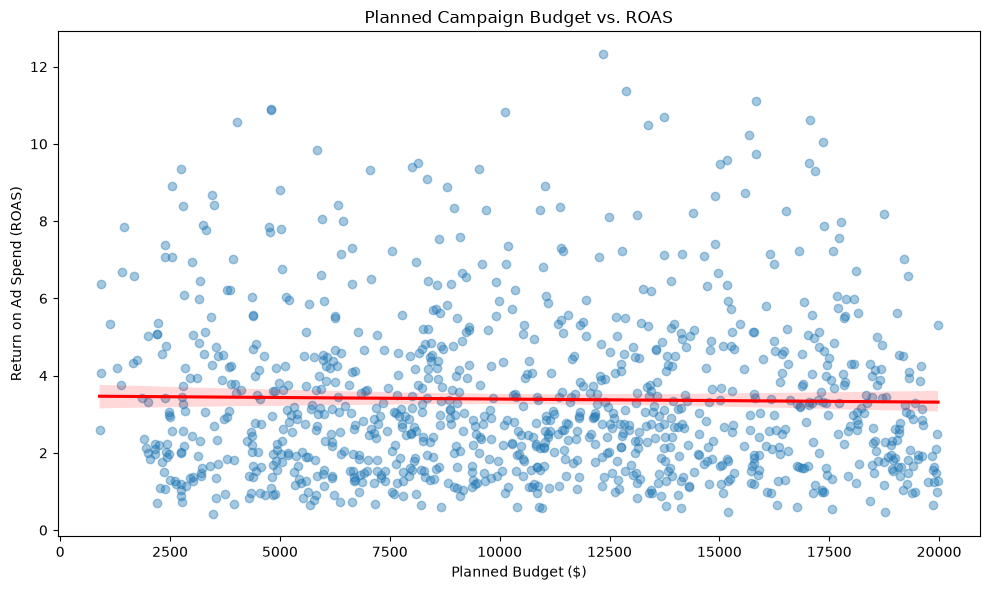

In [21]:

plt.figure(figsize=(10, 6))

sns.regplot(
    data=df,
    x="budget",
    y="roas",
    scatter_kws={"alpha": 0.4},
    line_kws={"color": "red"}
)

plt.title("Planned Campaign Budget vs. ROAS")
plt.xlabel("Planned Budget ($)")
plt.ylabel("Return on Ad Spend (ROAS)")
plt.tight_layout()

plt.show()

In [22]:

print("Correlation between planned budget and ROAS:")
print(df["budget"].corr(df["roas"]))

Correlation between planned budget and ROAS:
-0.019452929307019258



### Planned Budget vs. ROAS

The Pearson correlation between planned campaign budget and ROAS was -0.0195, indicating virtually no linear relationship between the two variables.

Higher planned budgets did not consistently correspond with higher campaign returns. This suggests that budget size alone is insufficient to explain campaign performance.

Correlation does not establish causation and does not rule out nonlinear relationships or interactions with other campaign characteristics.

In [23]:

df["budget_variance"] = df["spend"] - df["budget"]

df["budget_utilization"] = (
    df["spend"] / df["budget"]
) * 100

print("Average budget utilization:",
      df["budget_utilization"].mean())

print("Campaigns over budget:",
      (df["budget_variance"] > 0).sum())

print("Campaigns under budget:",
      (df["budget_variance"] < 0).sum())

print("Campaigns exactly on budget:",
      (df["budget_variance"] == 0).sum())

Average budget utilization: 87.59504231648607
Campaigns over budget: 149
Campaigns under budget: 851
Campaigns exactly on budget: 0



### Campaign Budget Utilization

Average budget utilization was 87.60% across the 1,000 campaigns. A total of 851 campaigns (85.1%) spent below their planned budgets, while 149 (14.9%) exceeded their budgets. No campaigns spent exactly their planned budget.

These findings indicate that most campaigns did not fully utilize their planned budgets. Further analysis is needed to determine whether reallocating unused budget could improve overall returns.

In [24]:

# Identify potential outliers using the interquartile range
for column in ["budget", "spend", "clicks", "conversions", "revenue", "roas"]:
    q1 = df[column].quantile(0.25)
    q3 = df[column].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = ((df[column] < lower) | (df[column] > upper)).sum()

    print(f"{column}: {outliers} potential outliers")

budget: 0 potential outliers
spend: 0 potential outliers
clicks: 39 potential outliers
conversions: 53 potential outliers
revenue: 49 potential outliers
roas: 33 potential outliers



### Outlier Detection

The Interquartile Range (IQR) method identified potential outliers in clicks (39), conversions (53), revenue (49), and ROAS (33).

No potential outliers were identified in budget or spend.

These observations were retained because unusually high campaign performance may reflect legitimate business outcomes. No records were removed solely because they exceeded the IQR thresholds.

In [25]:
# Define the information available before a campaign launches
features = [
    "channel",
    "objective",
    "budget",
    "campaign_duration_days",
    "start_year",
    "start_month",
    "start_quarter"
]

# Define the outcome we want to predict
X = df[features]
y = df["roas"]

print("Feature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)

X.head()

Feature dataset shape: (1000, 7)
Target dataset shape: (1000,)


,channel,objective,budget,campaign_duration_days,start_year,start_month,start_quarter
0,Display,Loyalty,15783,47,2023,9,3
1,Display,New Product,10637,27,2023,4,2
2,Affiliate,Brand,19605,26,2024,10,4
3,Affiliate,Spring Sale,12148,17,2023,10,4
4,Display,New Product,7439,31,2024,1,1


In [27]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

Training features: (800, 7)
Testing features: (200, 7)
Training targets: (800,)
Testing targets: (200,)


In [28]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Create and train the baseline model
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train[["budget"]], y_train)

# Generate predictions
baseline_predictions = baseline.predict(X_test[["budget"]])

# Evaluate performance
baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_predictions))
baseline_r2 = r2_score(y_test, baseline_predictions)

print("Baseline Model Performance")
print("MAE:", round(baseline_mae, 3))
print("RMSE:", round(baseline_rmse, 3))
print("R-squared:", round(baseline_r2, 3))

Baseline Model Performance
MAE: 1.544
RMSE: 1.99
R-squared: -0.003


In [29]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor

# Separate categorical and numerical features
categorical_features = ["channel", "objective"]
numerical_features = [
    "budget",
    "campaign_duration_days",
    "start_year",
    "start_month",
    "start_quarter"
]

# Prepare preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("numerical", "passthrough", numerical_features)
    ]
)

# Create the model pipeline
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        min_samples_leaf=3
    ))
])

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [30]:
# Generate predictions
rf_predictions = rf_model.predict(X_test)

# Evaluate performance
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_r2 = r2_score(y_test, rf_predictions)

print("Random Forest Model Performance")
print("MAE:", round(rf_mae, 3))
print("RMSE:", round(rf_rmse, 3))
print("R-squared:", round(rf_r2, 3))

Random Forest Model Performance
MAE: 1.248
RMSE: 1.675
R-squared: 0.289



### Random Forest Model Evaluation

The Random Forest model outperformed the baseline model on all three evaluation metrics.

- MAE improved from 1.544 to 1.248, a 19.2% reduction in average absolute prediction error.
- RMSE improved from 1.990 to 1.675, a 15.8% reduction.
- R² improved from -0.003 to 0.289, indicating that the model explains approximately 28.9% of the variation in test-set ROAS.

Although the Random Forest demonstrated improved predictive performance, substantial unexplained variation remains. Predictions should be treated as estimates rather than reliable guarantees of campaign performance.


In [31]:
# Extract feature names after preprocessing
feature_names = rf_model.named_steps["preprocessor"].get_feature_names_out()

# Extract Random Forest feature importance scores
importances = rf_model.named_steps["model"].feature_importances_

# Create a ranked table
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

print(feature_importance)

                                  Feature  Importance
2              categorical__channel_Email        0.19
0          categorical__channel_Affiliate        0.18
14                      numerical__budget        0.18
15      numerical__campaign_duration_days        0.14
3        categorical__channel_Paid search        0.09
17                 numerical__start_month        0.06
4             categorical__channel_Social        0.03
16                  numerical__start_year        0.02
18               numerical__start_quarter        0.02
8        categorical__objective_Clearance        0.02
6   categorical__objective_Back to School        0.01
1            categorical__channel_Display        0.01
5              categorical__channel_Video        0.01
9          categorical__objective_Holiday        0.01
13     categorical__objective_Spring Sale        0.01
7            categorical__objective_Brand        0.01
12     categorical__objective_Retargeting        0.01
10         categorical__obje


### Random Forest Feature Importance

The most influential individual features were Email (0.19), Affiliate (0.18), planned budget (0.18), and campaign duration (0.14).

Paid Search (0.09) and launch month (0.06) also contributed to predictions.

These results indicate that marketing channel, planned budget, and campaign duration were important predictors within the trained model. Feature importance reflects predictive contribution and does not establish causal relationships.

In [32]:
comparison = pd.DataFrame({
    "Actual ROAS": y_test.values,
    "Predicted ROAS": rf_predictions
})

comparison["Prediction Error"] = (
    comparison["Actual ROAS"] - comparison["Predicted ROAS"]
)

comparison.head(10)

,Actual ROAS,Predicted ROAS,Prediction Error
0,1.21,1.98,-0.77
1,7.78,4.20,3.58
2,0.59,1.92,-1.33
3,1.37,3.84,-2.47
4,3.95,5.81,-1.86
5,3.83,3.96,-0.13
6,1.82,4.19,-2.37
7,5.72,4.93,0.79
8,1.54,2.05,-0.51
9,1.95,1.88,0.07



### Actual vs. Predicted ROAS

A comparison of individual test-set predictions revealed variation in model accuracy.

The model underestimated some high-performing campaigns and overestimated some lower-performing campaigns. Other campaigns received relatively accurate predictions.

This suggests that the model captures general performance patterns but struggles to predict extreme outcomes. Individual predictions should therefore be interpreted cautiously.

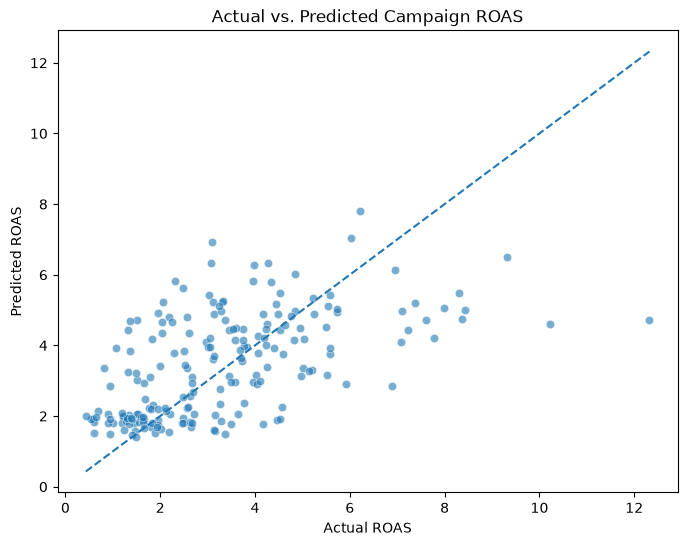

In [34]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=y_test,
    y=rf_predictions,
    alpha=0.6
)

# Add a perfect-prediction reference line
min_value = min(y_test.min(), rf_predictions.min())
max_value = max(y_test.max(), rf_predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual ROAS")
plt.ylabel("Predicted ROAS")
plt.title("Actual vs. Predicted Campaign ROAS")
plt.show()

In [35]:
# Generate predictions on training data
train_predictions = rf_model.predict(X_train)

# Calculate R-squared for both datasets
train_r2 = r2_score(y_train, train_predictions)
test_r2 = r2_score(y_test, rf_predictions)

print("Training R-squared:", round(train_r2, 3))
print("Testing R-squared:", round(test_r2, 3))
print("Difference:", round(train_r2 - test_r2, 3))

Training R-squared: 0.753
Testing R-squared: 0.289
Difference: 0.463



### Overfitting Assessment

The Random Forest achieved an R² of 0.753 on training data and 0.289 on testing data, producing a difference of 0.463.

This substantial performance gap indicates potential overfitting. The model learned patterns in the training dataset that did not generalize equally well to unseen campaigns.

Further model tuning is necessary to improve generalization.

In [37]:
rf_tuned = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=200,
        max_depth=8,
        min_samples_split=10,
        min_samples_leaf=8,
        random_state=42
    ))
])

# Train the revised model
rf_tuned.fit(X_train, y_train)

# Evaluate training and testing predictions
tuned_train_predictions = rf_tuned.predict(X_train)
tuned_test_predictions = rf_tuned.predict(X_test)

tuned_train_r2 = r2_score(y_train, tuned_train_predictions)
tuned_test_r2 = r2_score(y_test, tuned_test_predictions)

tuned_mae = mean_absolute_error(y_test, tuned_test_predictions)
tuned_rmse = np.sqrt(mean_squared_error(y_test, tuned_test_predictions))

print("Tuned Random Forest Performance")
print("Training R-squared:", round(tuned_train_r2, 3))
print("Testing R-squared:", round(tuned_test_r2, 3))
print("MAE:", round(tuned_mae, 3))
print("RMSE:", round(tuned_rmse, 3))

Tuned Random Forest Performance
Training R-squared: 0.559
Testing R-squared: 0.336
MAE: 1.211
RMSE: 1.619



### Random Forest Hyperparameter Tuning

The Random Forest was tuned by limiting tree depth and increasing the minimum observations required for splits and leaf nodes.

The tuned model improved test R² from 0.289 to 0.336, reduced MAE from 1.248 to 1.211, and reduced RMSE from 1.675 to 1.619.

The training/testing R² gap decreased from 0.464 to 0.223, indicating improved generalization and reduced overfitting.

The tuned model demonstrated the strongest test performance among the three models evaluated, although substantial unexplained variation remains.


In [38]:
tuned_comparison = pd.DataFrame({
    "Actual ROAS": y_test.values,
    "Predicted ROAS": tuned_test_predictions
})

tuned_comparison["Prediction Error"] = (
    tuned_comparison["Actual ROAS"] -
    tuned_comparison["Predicted ROAS"]
)

tuned_comparison.head(10)

,Actual ROAS,Predicted ROAS,Prediction Error
0,1.21,1.85,-0.64
1,7.78,4.44,3.34
2,0.59,1.90,-1.31
3,1.37,3.87,-2.50
4,3.95,5.80,-1.85
5,3.83,4.24,-0.41
6,1.82,3.92,-2.10
7,5.72,5.15,0.57
8,1.54,2.05,-0.51
9,1.95,2.07,-0.12



### Comparison of Original and Tuned Predictions

The tuned model produced modest improvements in several individual predictions, including campaigns 0, 1, 6, and 7.

However, it continued to struggle with unusually high and low ROAS outcomes. Some individual predictions became less accurate despite improvements in overall evaluation metrics.

This reinforces the importance of evaluating models across the full test dataset rather than relying on a small sample of predictions.


In [39]:
from sklearn.model_selection import cross_validate, KFold

# Create five different training/validation splits
kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate the tuned model
cv_results = cross_validate(
    rf_tuned,
    X_train,
    y_train,
    cv=kfold,
    scoring={
        "r2": "r2",
        "mae": "neg_mean_absolute_error",
        "rmse": "neg_root_mean_squared_error"
    }
)

# Display results for each fold
cv_summary = pd.DataFrame({
    "R-squared": cv_results["test_r2"],
    "MAE": -cv_results["test_mae"],
    "RMSE": -cv_results["test_rmse"]
})

print(cv_summary.round(3))

print("\nAverage cross-validation performance:")
print(cv_summary.mean().round(3))

print("\nStandard deviation:")
print(cv_summary.std().round(3))

   R-squared  MAE  RMSE
0       0.33 1.34  1.82
1       0.38 1.30  1.74
2       0.35 1.24  1.58
3       0.40 1.22  1.57
4       0.36 1.28  1.75

Average cross-validation performance:
R-squared   0.36
MAE         1.28
RMSE        1.69
dtype: float64

Standard deviation:
R-squared   0.02
MAE         0.05
RMSE        0.11
dtype: float64



### Five-Fold Cross-Validation

The tuned Random Forest was evaluated using five-fold cross-validation on the training dataset.

Average results:
- R²: 0.36 (standard deviation: 0.02)
- MAE: 1.28 (standard deviation: 0.05)
- RMSE: 1.69 (standard deviation: 0.11)

The relatively low standard deviations indicate consistent performance across the five validation folds.

The tuned Random Forest was selected as the final model because it outperformed the baseline and original Random Forest while demonstrating improved generalization.

On the separate held-out test dataset, the selected model achieved an R² of 0.336, MAE of 1.211, and RMSE of 1.619.


# Business Recommendations & Strategic Insights


## 1. Marketing Channel Allocation

### Key Finding

Email and Affiliate demonstrated the strongest weighted ROAS, at 5.25 and 4.98 respectively. Paid Search followed at 3.66. Display and Video had the lowest weighted returns, at 1.97 and 1.92.

### Recommendation

Prioritize evaluating additional investment opportunities in Email and Affiliate campaigns, where historical returns were strongest.

Maintain Paid Search as another channel for investment consideration. Review Display and Video campaign strategies to identify opportunities to improve targeting, creative execution, and conversion efficiency before increasing their budgets.

Lower-performing channels should not automatically be eliminated, as they may support objectives beyond immediate revenue generation.

### Business Consideration

These results are based on historical campaign performance and do not establish that reallocating budgets will produce the same returns in future campaigns. Additional testing is recommended before making substantial budget changes.



## 2. Campaign Budget Optimization

### Key Finding

Average budget utilization was 87.60%. Of the 1,000 campaigns analyzed, 851 spent below their planned budgets, while 149 exceeded their planned budgets.

### Recommendation

Implement more frequent budget monitoring to identify campaigns that consistently underspend or exceed their allocations.

Evaluate opportunities to reallocate unused budget toward campaigns demonstrating stronger performance, particularly within historically high-performing channels such as Email and Affiliate.

Establish spending thresholds and review processes to identify budget deviations before campaigns conclude.

### Business Consideration

Underspending does not automatically indicate inefficiency, and overspending does not necessarily indicate poor performance. Budget adjustments should consider campaign objectives, remaining duration, conversion performance, and incremental return rather than ROAS alone.



## 3. Channel and Campaign Objective Optimization

### Key Finding

Campaign performance varied considerably across channel and objective combinations.

Affiliate + Spring Sale achieved the highest average ROAS at 6.18, followed by Email + Clearance at 5.74 and Affiliate + Back to School at 5.72.

Conversely, Display + Spring Sale recorded the lowest average ROAS at 1.61.

### Recommendation

Use historical channel-objective performance to guide campaign planning.

Prioritize testing combinations that demonstrated stronger historical returns, particularly Affiliate campaigns supporting Spring Sale, Back to School, and Brand objectives, as well as Email Clearance campaigns.

Review lower-performing combinations to identify opportunities to improve audience targeting, messaging, and campaign execution.

### Business Consideration

These findings reflect historical associations rather than guaranteed future outcomes. Campaign objectives, audience characteristics, and business priorities should be considered before reallocating investment.



## 4. Predictive Analytics for Campaign Planning

### Key Finding

The tuned Random Forest model outperformed the baseline model and achieved a test R² of 0.336. Planned budget, campaign duration, and marketing channel indicators were among its most influential features.

### Recommendation

Use predictive modeling as an additional decision-support tool during campaign planning.

Before launching a campaign, marketing teams could use planned budget, channel, campaign objective, duration, and launch timing to generate an estimated ROAS.

These estimates could help identify campaigns that may warrant additional review, compare potential campaign configurations, and support more informed budget discussions.

### Business Consideration

The model explains approximately 33.6% of the variation in the held-out test data. Its predictions are not sufficiently accurate to serve as the sole basis for budget allocation. Human judgment, historical performance, and controlled campaign testing should remain part of the decision-making process.



## 5. Executive Summary

### Project Overview

This project analyzed 1,000 historical marketing campaigns to evaluate channel performance, campaign effectiveness, budget utilization, and opportunities for predictive analytics.

SQL and Python were used to investigate performance patterns, validate campaign metrics, and develop a Random Forest regression model to estimate campaign ROAS using pre-launch information.

### Key Findings

1. **Channel Performance:** Email and Affiliate achieved the highest weighted ROAS at 5.25 and 4.98, respectively.

2. **Budget Utilization:** Campaigns used an average of 87.60% of their planned budgets, with 85.1% spending below their allocations.

3. **Campaign Strategy:** Affiliate + Spring Sale and Email + Clearance were among the strongest channel-objective combinations.

4. **Predictive Modeling:** The tuned Random Forest achieved a test R² of 0.336, outperforming the baseline model and reducing overfitting.

### Strategic Recommendations

- Evaluate additional investment opportunities in historically high-performing channels.
- Improve budget monitoring and investigate opportunities to reallocate unused funds.
- Use historical channel-objective performance to inform campaign planning.
- Incorporate predictive analytics into campaign evaluation while retaining human oversight.
- Conduct controlled experiments to validate whether historical performance patterns translate into future results.

### Conclusion

The analysis demonstrates how marketing analytics and predictive modeling can support more informed campaign planning and budget decisions.

Although historical performance and predictive models provide useful insights, further testing is necessary before implementing substantial budget changes.
